# Bonus: 3D Energy Surface

:::{div}
:class: colab-badge
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/blinkletter/UsingPsi4v2/blob/main/ch2B-A-optimizing-3Dpath.ipynb)
:::


In [3]:
#| label: setup-2BA
#| tags: [remove-cell, remove-stdout]

####################################################
### Import Libraries and set up global variables ###
####################################################

from pathlib import Path
import sys

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Psi4 cannot be installed with pip. On Colab we first install conda
# (condacolab), which RESTARTS the session. After the restart, run
# this cell again and Psi4 will be installed with conda.
try:
    import psi4
except ImportError:
    if IN_COLAB:
        !pip -q install condacolab
        import condacolab
        condacolab.install()
        !mamba install -q -y -c conda-forge psi4
    import psi4

try:
    import py3Dmol
except ImportError:
    !pip -q install py3Dmol
    import py3Dmol

try:
    import rdkit
except ImportError:
    !pip -q install rdkit
    import rdkit

# Standard imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Style sheets and helper functions from the book's GitHub repository
if IN_COLAB:
    if not Path("styles/tufte.mplstyle").exists():
        !wget -q -N -P styles https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/styles/tufte.mplstyle
        !wget -q -N https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/psi4_helpers.py
    plt.style.use("styles/tufte.mplstyle")
    nproc = 2          # Colab gives you 2 cores
else:
    plt.style.use("styles/tufte.mplstyle")
    nproc = 4          # my own computer limit: 4 threads. Yours may vary. Adjust this number to your system's capabilities. Don't include efficiency cores as they are not well-suited for Psi4 calculations.

import psi4_helpers as ph

# All Psi4 .out and .log files go into the output folder
output_dir = Path("output/ch2/2B-optimizing")
output_dir.mkdir(exist_ok=True)


# Resources: house limits are 4 threads and 4 GB
psi4.set_num_threads(nproc)
psi4.set_memory("2 GB")

# 3D pictures: False = static images (as in the book); True = rotatable py3Dmol viewers
INTERACTIVE = True

In [4]:
#| label: optimize-2
#| class: scroll-input

# define the geometry of a water molecule in Z-matrix format
water = """
0 1                  # charge and multiplicity: 0 = neutral, 1 = singlet
H
O 1 1.0              # typical bond length for X-H bonds is 1.0 Å
H 2 1.0 1 109.0      # typical bond angle for sp3 is 109.0°
"""

mol = psi4.geometry(water)  # create a molecule object from the water geometry

print(f"Start:  r = {ph.bond_length(mol, 1, 2):.4f} Å\
      angle = {ph.bond_angle(mol, 3, 2, 1):.2f}°")

# optimize geometry and return the optimized energy, wavefunction, and optimization history
E_opt, wfn, history = psi4.optimize("hf/6-31g*",        
                                    molecule=mol, 
                                    return_wfn=True, 
                                    return_history=True
                                    )
print(f"Final:  r = {ph.bond_length(mol, 1, 2):.4f} Å     angle = {ph.bond_angle(mol, 3, 2, 1):.2f}°")
print(f"Final energy = {E_opt:.8f} hartree after {len(history['energy'])} steps")


Start:  r = 1.0000 Å      angle = 109.00°
Optimizer: Optimization complete!
Final:  r = 0.9472 Å     angle = 105.50°
Final energy = -76.01072062 hartree after 4 steps


### A Two-Dimensional Energy Surface

Earlier we [scanned one coordinate](#rigid-scan) with the angle held fixed. Water has three internal coordinates, but because both O–H bonds stay equal during this optimization, we can describe every step with just **two**: the O–H **bond length** and the H–O–H **bond angle**. The [code below](#scan-2d) calculates the energy on a **grid** of lengths and angles (399 single-point energies, about a minute), which maps out the **potential energy well**. The following cells draw the surface in 3D and as a contour map, and add the **path** the optimizer took, using the coordinates saved in `history`.

```{note} Psi4 settings in this cell
:class: dropdown
`E_grid[i, j]`
: A 2D *NumPy* array: each row is one angle and each column is one bond length. All energies are made relative to the optimized energy `E_opt`, so the bottom of the well is close to zero.
```

In [9]:
#| label: scan-2d
#| class: scroll-input

psi4.set_output_file(output_dir / "02B-opt-2Dscan.out", False)  # write output to a file, not the notebook

r_values     = np.linspace(0.89, 1.01, 41)    # O-H bond lengths from 0.89 to 1.01 Å
angle_values = np.linspace(98.0, 114.0, 33)     # H-O-H angles from 98 to 114°

E_grid = np.zeros((len(angle_values), len(r_values)))   # rows = angles, columns = distances

for i, angle in enumerate(angle_values):        # loop over the angles...
    for j, r in enumerate(r_values):            # ...and, for each angle, over the distances
        # make a new Z-matrix for each combination of r and angle
        scan_mol = psi4.geometry(f"""           
        0 1
        H
        O 1 {r}
        H 2 {r} 1 {angle}
        """)
        E_grid[i, j] = psi4.energy("hf/6-31g*", molecule=scan_mol)

# relative energies in kJ/mol, measured from the optimized structure
rel_E_grid = (E_grid - E_opt) * psi4.constants.hartree2kJmol
print(f"{E_grid.size} energies calculated")

1353 energies calculated


In [14]:
#| label: calc-path
#| class: scroll-input

# bond length and angle at each optimization step (history coordinates are in bohr)
path_r, path_angle = [], []
for coords in history["coordinates"]:
    xyz = np.asarray(coords) * psi4.constants.bohr2angstroms
    v1 = xyz[0] - xyz[1]                      # O -> H1  (atom order is H, O, H)
    v2 = xyz[2] - xyz[1]                      # O -> H2
    r1, r2 = np.linalg.norm(v1), np.linalg.norm(v2)
    path_r.append((r1 + r2) / 2)
    path_angle.append(np.degrees(np.arccos(np.dot(v1, v2) / (r1 * r2))))
path_E = (np.array(history["energy"]) - E_opt) * psi4.constants.hartree2kJmol

for n, (r, a, e) in enumerate(zip(path_r, path_angle, path_E), start=1):
    print(f"step {n}: r = {r:.4f} Å   angle = {a:6.2f}°   E = {e:6.2f} kJ/mol")


step 1: r = 1.0000 Å   angle = 109.00°   E =  15.76 kJ/mol
step 2: r = 0.9438 Å   angle = 103.56°   E =   0.40 kJ/mol
step 3: r = 0.9479 Å   angle = 105.64°   E =   0.00 kJ/mol
step 4: r = 0.9472 Å   angle = 105.50°   E =   0.00 kJ/mol


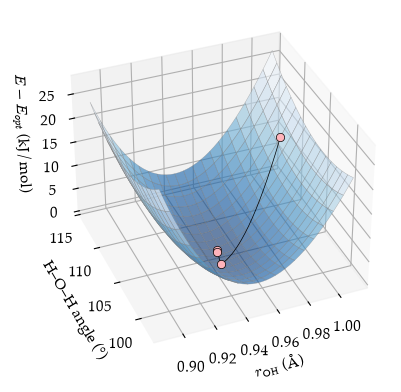

[np.float64(0.999999999999997), np.float64(0.9988527279303875), np.float64(0.9977054558607781), np.float64(0.9965581837911686), np.float64(0.995410911721559), np.float64(0.9942636396519496), np.float64(0.9931163675823401), np.float64(0.9919690955127306), np.float64(0.9908218234431212), np.float64(0.9896745513735117), np.float64(0.9885272793039022), np.float64(0.9873800072342928), np.float64(0.9862327351646832), np.float64(0.9850854630950738), np.float64(0.9839381910254643), np.float64(0.9827909189558548), np.float64(0.9816436468862454), np.float64(0.9804963748166359), np.float64(0.9793491027470264), np.float64(0.978201830677417), np.float64(0.9770545586078074), np.float64(0.9759072865381979), np.float64(0.9747600144685885), np.float64(0.973612742398979), np.float64(0.9724654703293695), np.float64(0.9713181982597601), np.float64(0.9701709261901506), np.float64(0.969023654120541), np.float64(0.9678763820509316), np.float64(0.9667291099813221), np.float64(0.9655818379117126), np.float64(0

In [20]:
#| label: 3d-plot
#| class: scroll-input

from scipy.interpolate import RegularGridInterpolator

# create 2D grids of x and y values to match E_grid
R, A = np.meshgrid(r_values, angle_values)    

# energy anywhere on the surface, interpolated from the grid (grid axes: angle, then r)
# surface_E will be a function that calculates energy at any x,y value.
surface_E = RegularGridInterpolator((angle_values, r_values), rel_E_grid, method="cubic")

# draw each step as a straight line in (r, angle), with heights taken from the surface
line_r, line_angle = [], []                # empty lists to create list objects
for k in range(len(path_r) - 1):           # for each line between points...
    t = np.linspace(0, 1, 50)                 # add 50 points from one step to the next
#    print(path_r[k] + t * (path_r[k+1] - path_r[k]))
    line_r.extend(path_r[k] + t * (path_r[k+1] - path_r[k]))  # add a list of 50 x values spaced between two energy points
    line_angle.extend(path_angle[k] + t * (path_angle[k+1] - path_angle[k])) # add a list of 50 y values spaced between two energy points
line_E = surface_E(np.column_stack([line_angle, line_r]))

fig, ax3d = plt.subplots(figsize=(5, 4),
                         subplot_kw={"projection": "3d", 
                                     "computed_zorder": False})
# left: 3D surface with the optimization path on top
ax3d.plot_surface(R, A, rel_E_grid, cmap="Blues_r", alpha=0.6, rstride=2, cstride=2,
                  linewidth=0.3, edgecolor="grey", zorder=1)
# path along the surface
ax3d.plot(line_r, line_angle, line_E,
          color="black", linewidth=0.5, zorder=2)
# the optimization steps
ax3d.plot(path_r, path_angle, path_E, 
          linestyle="none", marker="o",
          markerfacecolor="#FFB3BA", 
          markeredgecolor="black", 
          markeredgewidth=0.5, zorder=3)
# style the plot
ax3d.set_xlabel(r"$r_{\mathrm{OH}}$ (Å)")
ax3d.set_ylabel("H–O–H angle (°)")
ax3d.set_zlabel(r"$E - E_{opt}$ (kJ/mol)")
# view angle
ax3d.view_init(elev=35, azim=-112)  # adjust the view angle for better visibility

plt.savefig(output_dir / "02B-opt-3Dscan.png", dpi=300, bbox_inches="tight")
plt.show()

print(line_r)

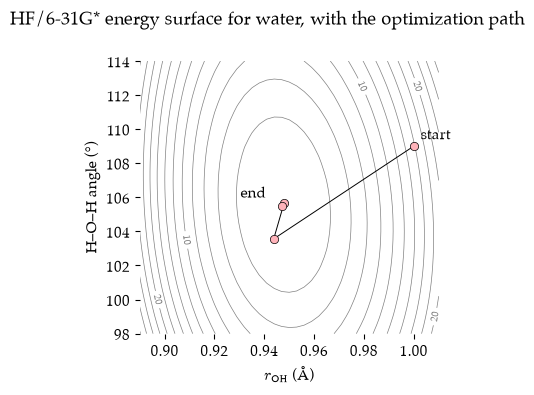

In [13]:
#| label: 2d-plot
#| class: scroll-input

fig, ax2d = plt.subplots(figsize=(4, 4))

# right: contour map (looking straight down on the surface) with the same path
levels = np.arange(0, rel_E_grid.max(), 2.0)
cs = ax2d.contour(R, A, rel_E_grid, levels=levels, colors="grey", linewidths=0.5, zorder=1)
ax2d.clabel(cs, levels[::5], fontsize=7, fmt="%.0f")
ax2d.plot(path_r, path_angle, color="black", linewidth=0.7, marker="o",
          markerfacecolor="#FFB3BA", markeredgecolor="black", markeredgewidth=0.5, zorder=2)
ax2d.annotate("start", (path_r[0], path_angle[0]), xytext=(5, 5), textcoords="offset points")
ax2d.annotate("end", (path_r[-1], path_angle[-1]), xytext=(-30, 6), textcoords="offset points")
ax2d.set_xlabel(r"$r_{\mathrm{OH}}$ (Å)")
ax2d.set_ylabel("H–O–H angle (°)")

fig.suptitle("HF/6-31G* energy surface for water, with the optimization path")
plt.savefig(output_dir / "02B-opt-2Dscan.png", dpi=300, bbox_inches="tight")
plt.show()

The first step **overshoots**: it jumps from the start (1.00 Å, 109°) past the bottom of the well, to an angle that is a little too small. The next steps **correct** this and settle at the minimum (0.947 Å, 105.5°). Notice that the well is **steep** along the bond length and **shallow** along the angle. Stretching a bond costs much more energy than bending it by the same proportion.